This notebook demonstrates the process of JPEG image compression using the Discrete Cosine Transform (DCT) and quantization techniques. The workflow includes loading an image, separating its color channels, applying DCT to blocks of the image, quantizing the DCT coefficients, and reconstructing the image using the inverse DCT. Chrominance subsampling is performed to reduce data in color channels, mimicking the JPEG standard. The notebook also calculates metrics such as PSNR, MSE, and SSIM to evaluate the quality of the compressed image compared to the original. Visualizations are provided to compare the original and compressed images, and file sizes are reported to illustrate the effectiveness of compression.

In [28]:
import scipy
import numpy as np
import skimage
import matplotlib.pyplot as plt
import cv2

In [29]:
image_path = "https://upload.wikimedia.org/wikipedia/en/7/7d/Lenna_%28test_image%29.png"

In [30]:
from skimage import io

In [31]:
image = io.imread(image_path)

In [32]:
def channel_separate(image):
    y = image[:,:,0]
    c_b = image[:,:,1]
    c_r = image[:,:,2]
    return y, c_b, c_r

In [33]:
def average(image, kernel_size):
    height, width = image.shape
    kernel_height, kernel_width = kernel_size
    pooled = np.zeros_like(image, dtype=np.float32)
    
    for i in range(0, height, kernel_height):
        for j in range(0, width, kernel_width):
            patch = image[i:i+kernel_height, j:j+kernel_width]
            avg = np.mean(patch, dtype=np.float32)
            pooled[i:i+kernel_height, j:j+kernel_width] = avg

    return pooled.astype(image.dtype)

In [34]:
def dct(image):
    height, width = image.shape
    block_size = 8
    output = np.zeros_like(image, dtype=np.float32)
    
    for i in range(0, height, block_size):
        for j in range(0, width, block_size):
            patch = image[i:i+block_size, j:j+block_size]
            if patch.shape == (block_size, block_size):  # ensure full block
                dct_patch = scipy.fft.dct(scipy.fft.dct(patch.T, norm='ortho').T, norm='ortho')
                output[i:i+block_size, j:j+block_size] = dct_patch

    return output

In [35]:
def idct(image):
    height, width = image.shape
    block_size = 8
    output = np.zeros_like(image, dtype=np.float32)
    
    for i in range(0, height, block_size):
        for j in range(0, width, block_size):
            patch = image[i:i+block_size, j:j+block_size]
            if patch.shape == (block_size, block_size):  # ensure full block
                idct_patch = scipy.fft.idct(scipy.fft.idct(patch.T, norm='ortho').T, norm='ortho')
                output[i:i+block_size, j:j+block_size] = idct_patch

    return output

In [36]:
Q = np.array([[16, 11, 10, 16, 24, 40, 51, 61],
[12, 12, 14, 19, 26, 58, 60, 55],
[14, 13, 16, 24, 40, 57, 69, 56],
[14, 17, 22, 29, 51, 87, 80, 62],
[18, 22, 37, 56, 68, 109, 103, 77],
[24, 35, 55, 64, 81, 104, 113, 92],
[49, 64, 78, 87, 103, 121, 120, 101],
[72, 92, 95, 98, 112, 100, 103, 99]])

In [37]:
def blockwise_quantize(dct_img, Q):
    h, w = dct_img.shape
    out = np.zeros_like(dct_img)
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            out[i:i+8, j:j+8] = np.round(dct_img[i:i+8, j:j+8] / Q)
    return out

def blockwise_dequantize(q_img, Q):
    h, w = q_img.shape
    out = np.zeros_like(q_img)
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            out[i:i+8, j:j+8] = q_img[i:i+8, j:j+8] * Q
    return out


In [38]:
import cv2
import numpy as np
import scipy.fft

def jpeg_compress(img, Q, subsample=True):
    # Pad image to multiple of 8
    def pad(img):
        h, w = img.shape[:2]
        h_pad = (8 - h % 8) % 8
        w_pad = (8 - w % 8) % 8
        return cv2.copyMakeBorder(img, 0, h_pad, 0, w_pad, cv2.BORDER_REPLICATE)

    img = pad(img)
    height, width = img.shape[:2]

    # Convert to YCrCb and separate channels
    y, cb, cr = channel_separate(cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb))

    # Subsample chroma channels (4:2:0)
    if subsample:
        cb = average(cb, (2, 2))
        cr = average(cr, (2, 2))

    # Centering around zero
    y_dct = dct(y.astype(np.float32) - 128)
    cb_dct = dct(cb.astype(np.float32) - 128)
    cr_dct = dct(cr.astype(np.float32) - 128)

    y_quantized  = blockwise_quantize(y_dct, Q)
    cb_quantized = blockwise_quantize(cb_dct, Q)
    cr_quantized = blockwise_quantize(cr_dct, Q)

    y_dequant  = blockwise_dequantize(y_quantized, Q)
    cb_dequant = blockwise_dequantize(cb_quantized, Q)
    cr_dequant = blockwise_dequantize(cr_quantized, Q)


    # Inverse DCT and add 128 back
    y_idct  = idct(y_dequant) + 128
    cb_idct = idct(cb_dequant) + 128
    cr_idct = idct(cr_dequant) + 128

    # Upsample chroma channels if subsampled
    if subsample:
        cb_idct = cv2.resize(cb_idct, (width, height), interpolation=cv2.INTER_LINEAR)
        cr_idct = cv2.resize(cr_idct, (width, height), interpolation=cv2.INTER_LINEAR)


    # Clip to 0-255 and convert to uint8
    y_final  = np.clip(y_idct, 0, 255).astype(np.uint8)
    cb_final = np.clip(cb_idct, 0, 255).astype(np.uint8)
    cr_final = np.clip(cr_idct, 0, 255).astype(np.uint8)

    # Merge channels and convert back to BGR
    compressed_ycrcb = cv2.merge((y_final, cb_final, cr_final))
    compressed_img = cv2.cvtColor(compressed_ycrcb, cv2.COLOR_YCrCb2BGR)

    return compressed_img


In [39]:
def calculate_psnr(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

In [49]:
def calculate_mse(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    return mse

import os

def file_size_on_disk(original_img, compressed_img, filename_prefix="img"):
    cv2.imwrite(f"{filename_prefix}_original.jpg", original_img)
    cv2.imwrite(f"{filename_prefix}_compressed.jpg", compressed_img)

    original_size = os.path.getsize(f"{filename_prefix}_original.jpg")
    compressed_size = os.path.getsize(f"{filename_prefix}_compressed.jpg")

    return original_size, compressed_size


def ssim(original, compressed):
    from skimage.metrics import structural_similarity as ssim
    original_gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    compressed_gray = cv2.cvtColor(compressed, cv2.COLOR_BGR2GRAY)
    return ssim(original_gray, compressed_gray)

def rms_error(original, compressed):
    return np.sqrt(np.mean((original - compressed) ** 2))

In [41]:
compressed_image = jpeg_compress(image, Q, subsample=True)

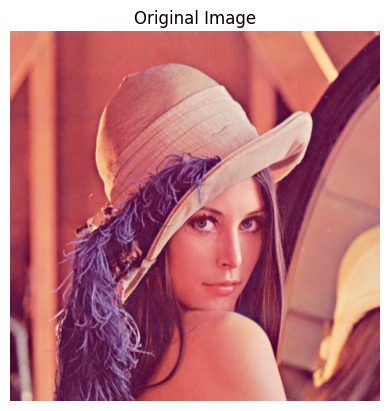

In [47]:
plt.imshow(image, cmap="grey")
plt.axis("off")
plt.savefig("original_image.png", bbox_inches='tight', pad_inches=0)
plt.title("Original Image")
plt.show()


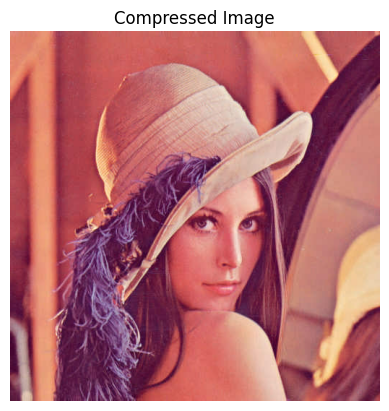

In [45]:
plt.imshow(compressed_image, cmap="grey")
plt.axis("off")
plt.savefig("compressed_image.png", bbox_inches='tight', pad_inches=0)
plt.title("Compressed Image")
plt.show()


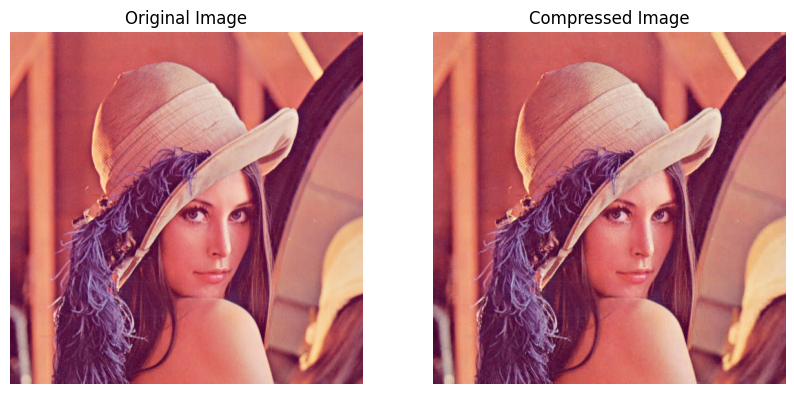

In [ ]:
plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image, cmap="grey")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.title("Compressed Image")
plt.imshow(compressed_image, cmap="grey")
plt.axis("off")
plt.show()

In [50]:
psnr = calculate_psnr(image, compressed_image)
mse = calculate_mse(image, compressed_image)
original_size, compressed_size = file_size_on_disk(image, compressed_image)
ssim_value = ssim(image, compressed_image)
print(f"PSNR: {psnr} dB")
print(f"MSE: {mse}")
print(f"SSIM: {ssim_value}")
print(f"Original Size: {original_size / 1024:.2f} KB")
print(f"Compressed Size: {compressed_size / 1024:.2f} KB")

PSNR: 33.90069948302834 dB
MSE: 26.485636393229168
SSIM: 0.9068711028685186
Original Size: 111.50 KB
Compressed Size: 63.28 KB
